# Hamming (Code theory)
## Information theory and coding - Dr. R. Sobhani - University of Isfahan - 1403/1404

By: Davoud Nosrati

## Algorithm

1. $H$ : \
0 0 0 ... 1 \
0 1 1 ... 1 \
1 0 1 ... 1 
2. Swap columns to get $H_s$ = [$-A^T$ | $I$].
3. Form $G_s$ = [$I$ | $A$].
4. Swap columns in the same order as step 2 to get $G$.

> Note: You can use both ($G_s$, $H_s$) and ($G$, $H$). Both pairs are valid. 
- The pitfall of ($G_s$, $H_s$): The syndrome (like [0, 1, 1]) no longer means 6. Because the order of columns in $H_s$ is not the 1, 2, 3 ... 7. It's changed. We have to transpose $H_s$ and check in which index this very syndrome lies.
- The pitfall of ($G$, $H$): The encoded data (generated by multiplying in $G$) is no longer in the form "data bits + redundancy bits". Meaning, data won't come first anymore. It'll be spread in between redundancy bits and that's a problem when we decode the encoded data blocks.

## Imports

In [1]:
import random
from copy import deepcopy
import math
import numpy as np
from scipy.optimize import root_scalar


## Utils

In [26]:
def generate_H_transpose(r: int, n: int) -> list[list[int]]:
    """Generates the parity-check matrix H for a Hamming code of length 2^r - 1."""
    return [[int(bit) for bit in f"{i:0{r}b}"] for i in range(1, n+1)]

def transpose(matrix: list[list[int]]) -> list[list[int]]:
    """Transposes a matrix."""
    return [[matrix[j][i] for j in range(len(matrix))] for i in range(len(matrix[0]))]


def generate_H(r: int, n: int) -> list[list[int]]:
    """Generates the parity-check matrix H for a Hamming code of length 2^r - 1."""
    H_transposed = generate_H_transpose(r, n)
    H = transpose(H_transposed)
    return H


def get_swap_pairs(r: int, n: int) -> list[tuple[int, int]]:
    swap_pairs = list()
    for i in range(r):
        # -1 is for making them 0-based
        swap_pairs.append((2**i - 1, n - i - 1))

    return swap_pairs


def generate_G(r: int, n: int, A: list[list[int]]) -> list[list[int]]:
    """Generates the generator matrix G for a Hamming code."""
    identity = identity_matrix(n - r)
    G = append_matrices(identity, A)
    return G


def swap_columns(matrix: list[list[int]], swap_pairs: list[tuple[int, int]]) -> list[list[int]]:
    """Swaps two columns in a matrix. Pairs are 1-indexed."""
    new_matrix = deepcopy(matrix)
    for (col1, col2) in swap_pairs:
        for row in new_matrix:
            row[col1], row[col2] = row[col2], row[col1]
    return new_matrix


def puncture_column(matrix: list[list[int]], start: int, end: int) -> list[list[int]]:
    new_matrix = list()
    for row in matrix:
        new_row = row[start:end]
        new_matrix.append(new_row)
    return new_matrix

def identity_matrix(n: int) -> list[list[int]]:
    return [[1 if i == j else 0 for j in range(n)] for i in range(n)]

def append_matrices(A: list[list[int]], B: list[list[int]]) -> list[list[int]]:
    return [a + b for a, b in zip(A, B)]

def multiply_matrices(A: list[list[int]], B: list[list[int]]) -> list[list[int]]:
    """Multiplies two matrices A and B."""
    result = [[0 for _ in range(len(B[0]))] for _ in range(len(A))]
    for i in range(len(A)):
        for j in range(len(B[0])):
            for k in range(len(B)):
                result[i][j] ^= A[i][k] & B[k][j]
    return result


def pad(raw_data: list[int], k: int) -> list[int]:
    data_length = len(raw_data)
    padded_data = deepcopy(raw_data)
    padding = math.ceil(data_length / k) * k - data_length
    if padding != 0:
        padded_data += [0 for _ in range(padding)]
    return padded_data, padding

def depad(data: list[int], padding: int) -> list[int]:
    """Removes the padding from the data."""
    if padding == 0:
        return data
    return data[:-padding] if padding > 0 else data

def encode(data: list[int], G: list[list[int]]) -> list[int]:
    encoded_data = list()
    data_length = len(data)
    k = len(G)
    for i in range(0, data_length, k):
        data_block = [data[i:i+k]]
        encoded_block = multiply_matrices(data_block, G)[0]
        encoded_data.extend(encoded_block)
    return encoded_data


def noise(encoded_data: list[int], bit_flip_probability) -> list[int]:
    data_length = len(encoded_data)
    noised_data = list()
    channel_noise = random.choices([1, 0], [bit_flip_probability, 1 - bit_flip_probability], k=data_length)

    for i in range(data_length):
        noised_data.append(encoded_data[i] ^ channel_noise[i])
    return noised_data


def correct(noisy_data: list[int], H: list[list[int]]) -> list[int]:
    data_length = len(noisy_data)
    n = len(H[0])
    transposed_H = transpose(H)
    decoded_data = deepcopy(noisy_data)
    for i in range(0, data_length, n):
        data_block = [noisy_data[i:i+n]]
        syndrome = multiply_matrices(data_block, transposed_H)[0]
        # syndrome.reverse()
        error_index = None
        for index, row in enumerate(transposed_H):
            if syndrome == row:
                error_index = index
                break
        if error_index is not None:
            decoded_data[i + error_index] ^= 1
    return decoded_data


def decode(corrected_data: list[int], r: int) -> list[int]:
    """Decodes the corrected data by removing the parity bits."""
    n = 2**r - 1
    k = n - r
    decoded_data = []
    for i in range(0, len(corrected_data), n):
        decoded_data.extend(corrected_data[i:i+k])
    return decoded_data


def hamming_distance(data1: list[int], data2: list[int]) -> int:
    """Calculates the Hamming distance between two binary sequences."""
    return sum(bit1 != bit2 for bit1, bit2 in zip(data1, data2))


def get_G_H(r: int) -> tuple[list[list[int]], list[list[int]]]:
    n = 2 ** r - 1
    
    H = generate_H(r=r, n=n)
    swap_pairs = get_swap_pairs(r=r, n=n)
    swapped_H = swap_columns(H, swap_pairs)
    negative_transposed_A = puncture_column(swapped_H, start=0, end=n-r)
    A = transpose(negative_transposed_A)
    swapped_G = generate_G(r=r, n=n, A=A)


    print(f"{"-" * 5 + ""}>   H:")
    for row in H:
        print(row)
    print(f"{"-" * 5 + ""}>   G:")
    for row in swapped_G:
        print(row)

    GH_transpose = multiply_matrices(swapped_G, transpose(swapped_H))
    is_zero = 0
    for row in GH_transpose:
        is_zero += sum(row)
    
    print(f"{"-" * 5 + ""}>   Ensuring GH^T=0:")
    print(is_zero == 0)

    return swapped_G, swapped_H

def solve_for_p(r):
    def H(p):
        if p <= 0 or p >= 1:
            return 0.0
        return p * np.log2(p) + (1 - p) * np.log2(1 - p)

    n = 2 ** r - 1
    k = n - r
    C = k / n

    return root_scalar(lambda p: 1 + H(p) - C, bracket=[1e-10, 0.5 - 1e-10]).root


def normal_print_data(to_print: list[int]) -> None:
    """Prints the data in a normal way."""
    for i in range(len(to_print)):
        print(to_print[i], end=" ")
    print()


def pretty_print_data(to_print: list[int], compare_with: list[int]) -> None:
    """Prints the data in a formatted way."""
    RED = "\033[91m"
    RESET = "\033[0m"
    for i in range(len(to_print)):
        if to_print[i] != compare_with[i]:
            print(f"{RED}{to_print[i]}{RESET}", end=" ")
        else:
            print(to_print[i], end=" ")
    print()


def simulate_hamming_code(G: list[list[int]], H: list[list[int]], raw_data_length: int, bit_flip_probability: float):
    n = len(G[0])
    k = len(G)
    r = n - k

    raw_data = [random.randint(0, 1) for _ in range(raw_data_length)]
    raw_data = [int(bit) for bit in raw_data]

    padded_data, padding = pad(raw_data=raw_data, k=k)
    encoded_data = encode(padded_data, G=G)
    noisy_data = noise(encoded_data=encoded_data, bit_flip_probability=bit_flip_probability)
    corrected_data = correct(noisy_data=noisy_data, H=H)
    decoded_data = decode(corrected_data, r=r)
    depadded_data = depad(decoded_data, padding)
    error_count = hamming_distance(depadded_data, raw_data)
    error_rate = error_count / len(depadded_data)
    return error_rate

def plot_xy(xy_tuple: list[tuple[float, float]], shannon_p: float = None):
    import matplotlib.pyplot as plt

    x = [pair[0] for pair in xy_tuple]
    y = [pair[1] for pair in xy_tuple]

    plt.figure(figsize=(14, 6))
    plt.plot(x, y, marker='o')
    plt.title('Error Rate vs Bit Flip Probability')
    plt.ylabel('Error Rate')
    plt.xlabel('(1-p)/p')
    plt.xscale('log')
    plt.yscale('symlog')
    plt.grid()
    plt.axvline(
        x=(1 - shannon_p) / shannon_p, color="r", linestyle="--", label="x = 3/4"
    )
    plt.show()

## Main Runner

---------- Hamming code [15, 11, 3]_2 ----------
----->   H:
[0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1]
[0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1]
[0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1]
[1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1]
----->   G:
[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1]
[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0]
[0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1]
[0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1]
[0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1]
[0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0]
[0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1]
[0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1]
----->   Ensuring GH^T=0:
True
shannon p is:  0.0454321625536753


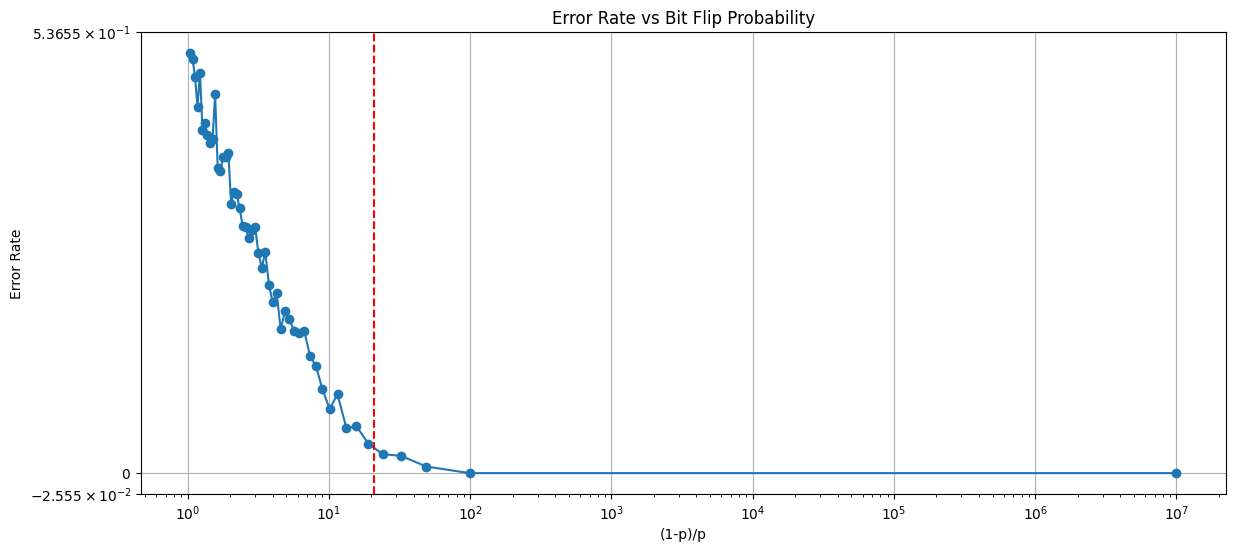

In [ ]:
def main():
    r = 4#int(input("Enter r for the Hamming code: "))
    n = 2 ** r - 1
    k = n - r
    raw_data_length = 1000# int(input("Enter the length of random data: "))
    probability_start = 1
    probability_end = 50
    qq = [1e-5]
    qq.extend([i for i in range(1, 50)])


    print(f"{"-" * 10} Hamming code [{n}, {k}, 3]_2 {"-" * 10}")
    G, H = get_G_H(r=r)

    xy_tuple = []

    # for i in range(probability_start, probability_end + 1):
    for i in qq:
        bit_flip_probability = i / 100
        error_rate = simulate_hamming_code(G=G, H=H, raw_data_length=raw_data_length, bit_flip_probability=bit_flip_probability)
        
        x = (1 - bit_flip_probability) / bit_flip_probability
        x = round(x, 6)
        y = error_rate

    shannon_p = solve_for_p(r=r)
    print("shannon p is: ", shannon_p)
    #TODO plot function has two bugs. x and y axis should be checked. A IS NOT right
    plot_xy(xy_tuple, shannon_p=shannon_p)

main()


## Playground

In [9]:
# print("dym ")
# tt = multiply_matrices(
#     A=[
#         [1, 0, 0, 0, 0, 1, 1],
#         [0, 1, 0, 0, 1, 0, 1],
#         [0, 0, 1, 0, 1, 1, 0],
#         [0, 0, 0, 1, 1, 1, 1]
#     ],
#     B=transpose(
#         [
#             [1, 0, 1, 0, 1, 0, 1],
#             [0, 1, 1, 0, 0, 1, 1],
#             [0, 0, 0, 1, 1, 1, 1],             
#         ]
#     )
# )
# for t in tt:
#     print(t)

# def ppp(r: int, n: int) -> list[list[int]]:
#     """Generates the parity-check matrix H for a Hamming code of length 2^r - 1."""
#     return [[int(bit) for bit in f"{i:0{r}b}"[::-1]] for i in range(1, n+1)]

# s = ppp(3, 7)
# s = transpose(s)
# print("Hello")
# for r in s:
#     print(" ".join(map(str, r)))

# d = """
# 1 0 1 1 1 0 1 0 1 0 1
# 0 1 1 1 0 1 1 0 0 1 1
# 1 1 1 0 0 0 0 1 1 1 1
# 0 0 0 0 1 1 1 1 1 1 1
# """

# d = """
# 1 1 0 1
# 1 0 1 1
# 0 1 1 1
# """

# d = [list(map(int, line.split())) for line in d.strip().split('\n')]
# d = transpose(d)
# for r in d:
#     print(" ".join(map(str, r)))
# # create I and append it to d
# I = [[1 if i == j else 0 for j in range(len(d))] for i in range(len(d))]
# for i in range(len(d)):
#     d[i].extend(I[i])
# for r in d:
#     print(" ".join(map(str, r)))
# print("Above is G")

# gs = """1 0 0 0 1 0 0 1 0 0 0 0 0 0 0
# 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0
# 1 1 0 0 0 0 1 1 0 0 0 0 0 0 0
# 1 1 0 1 0 0 0 0 0 0 0 0 0 0 0
# 1 0 1 0 0 0 0 0 1 0 0 0 0 0 0
# 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0
# 1 1 1 0 0 0 0 0 0 0 1 0 0 0 0
# 0 0 1 0 0 0 0 1 0 0 0 1 0 0 0
# 1 0 1 0 0 0 0 1 0 0 0 0 1 0 0
# 0 1 1 0 0 0 0 1 0 0 0 0 0 1 0
# 1 1 1 0 0 0 0 1 0 0 0 0 0 0 1
# """

# gs = """1 1 1 0 0 0 0
# 1 0 0 1 1 0 0
# 0 1 0 1 0 1 0
# 1 1 0 1 0 0 1
# """

# gs = [list(map(int, line.split())) for line in gs.strip().split('\n')]
# print(gs)
# print("{" + ", ".join("{" + ", ".join(map(str, row)) + "}" for row in gs) + "}")


# import sympy

# # Define the matrix using a list of lists
# matrix_list =[[1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0], 
#             [0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0], 
#             [1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0], 
#             [1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 
#             [1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0], 
#             [0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0], 
#             [1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0], 
#             [0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0], 
#             [1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0], 
#             [0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0], 
#             [1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1]]
# matrix_list = [[1, 1, 1, 0, 0, 0, 0],
#                 [1, 0, 0, 1, 1, 0, 0],
#                 [0, 1, 0, 1, 0, 1, 0], 
#                 [1, 1, 0, 1, 0, 0, 1]]


# # Create a SymPy Matrix object
# M = sympy.Matrix(matrix_list)

# print("Original Matrix:")
# sympy.pprint(M) # Use sympy's pretty printer

# # Calculate the reduced row echelon form
# rref_matrix, pivot_columns = M.rref()

# print("\n" + "="*40 + "\n")
# print("Reduced Row Echelon Form (RREF):")
# sympy.pprint(rref_matrix)

# print("\nPivot column indices:", pivot_columns)


G = """1 0 0 0 0 0 0 0 0 0 0 1 1 0 0
0 1 0 0 0 0 0 0 0 0 0 1 0 1 0
0 0 1 0 0 0 0 0 0 0 1 0 1 1 0
0 0 0 1 0 0 0 0 0 0 0 0 1 1 0
0 0 0 0 1 0 0 0 0 0 1 0 0 1 0
0 0 0 0 0 1 0 0 0 0 1 0 1 0 0
0 0 0 0 0 0 1 0 0 0 1 1 0 0 0
0 0 0 0 0 0 0 1 0 0 1 1 1 1 0
0 0 0 0 0 0 0 0 1 0 1 1 0 1 0
0 0 0 0 0 0 0 0 0 1 1 1 1 0 0
0 0 0 0 0 0 0 0 0 0 0 1 1 1 1"""

G = [list(map(int, line.split())) for line in G.strip().split('\n')]

H = """
1 0 0 0 1 1 0 1 1 0 1 1 0 1 0
0 1 0 0 1 0 1 1 0 1 1 0 1 1 0
0 0 1 0 0 1 1 0 1 1 1 0 0 1 1
0 0 0 1 0 0 0 1 1 1 1 0 1 0 1"""

# H = """
# 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1
# 0 1 1 0 0 1 1 0 0 1 1 0 0 1 1
# 0 0 0 1 1 1 1 0 0 0 0 1 1 1 1
# 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1
# """

H = [list(map(int, line.split())) for line in H.strip().split('\n')]

gg = multiply_matrices(G, transpose(H))
print("GH^T:")
for row in gg:
    print(" ".join(map(str, row)))

tt = multiply_matrices([[1,1,1,1,1,1,1,1,1,1,1]], G)
print(tt)
print(multiply_matrices(tt, transpose(H)))

GH^T:
0 1 0 1
0 0 1 0
0 1 1 0
1 0 1 0
1 1 0 1
0 0 0 0
0 0 0 1
0 0 0 1
0 0 1 0
0 1 0 1
0 0 0 0
[[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]
[[0, 0, 0, 1]]


In [19]:
a = random.choices([1, 0], [0.1, 0.9], k=20)
print(a)

[0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0]
